# RQ2 — What does progressive redundancy reduction actually do to functional prediction?

## Scientific question

**How does progressively reducing sequence redundancy alter predictive performance, and is the observed loss explained only by reduced data quantity or also by changes in the structure/diversity of the training evidence?**

Redundancy threshold:

\[
R \in \{90,70,50,30\}
\]

where lower `R` corresponds to more aggressive redundancy reduction.

This notebook analyzes the complete supervised benchmark while **holding `S` fixed** whenever the effect of `R` is estimated.

The goals are to determine:

1. the complete performance trajectory across `R90 → R70 → R50 → R30`;
2. all six possible `R` contrasts at every fixed `S`;
3. whether degradation is monotonic, threshold-like, saturated, or non-monotonic;
4. which tasks, representations, and learners are most redundancy-sensitive;
5. where the largest redundancy transition occurs;
6. how much performance is retained relative to `R90`;
7. how reductions in training entities and sequence clusters track performance loss;
8. whether the same amount of data removal produces comparable predictive loss across model families.

> **Scope rule:** this notebook treats `S` as a conditioning variable. Formal comparison of the magnitude of `R` versus `S`, and full `R×S` interaction analysis, belong to later RQs.

## Interpretation contract

Native test membership can change across `R` because redundancy reduction changes the dataset before splitting. Therefore:

- `R` contrasts are **native-test factorial contrasts**, not entity-level paired comparisons;
- the full common-test sensitivity analysis across `R` is reserved for the dedicated common-test RQ;
- MCC is the primary supervised metric;
- AP is interpreted together with prevalence, and normalized AP skill is used for binary-task cross-condition comparisons;
- for low-support tasks such as VAL, support changes must be considered explicitly.

The main scientific target is not merely “lower R lowers performance”, but **the shape and context dependence of the redundancy-response curve**.

In [1]:
from pathlib import Path
import warnings
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 250)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 250)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]

TASK_PATHS = {
    "global_easy": "global_easy",
    "global_hard": "global_hard",
    "global_mixed": "global_mixed",
    "subtype_endolysin": "subtype_binary/endolysin",
    "subtype_depolymerase": "subtype_binary/depolymerase",
    "subtype_val": "subtype_binary/virion_associated_lytic_enzyme",
    "multiclass_clean": "multiclass_clean",
}

BINARY_TASKS = [
    "global_easy",
    "global_hard",
    "global_mixed",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
]

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_supervised/stage12a").is_dir()
            and (candidate / "results/analysis_supervised/stage12b").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate project root containing stage12a and stage12b outputs."
    )

ROOT = find_project_root()
STAGE12A = ROOT / "results/analysis_supervised/stage12a"
STAGE12B = ROOT / "results/analysis_supervised/stage12b"
CACHE_DIR = ROOT / "results/analysis_supervised/notebook_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)

ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass


In [2]:
master = pd.read_csv(
    STAGE12A / "supervised_master_results.tsv",
    sep="\t",
    low_memory=False,
)

r_deltas = pd.read_csv(
    STAGE12B / "rs_redundancy_deltas_fixed_S.tsv",
    sep="\t",
    low_memory=False,
)

surfaces = pd.read_csv(
    STAGE12B / "rs_native_surfaces.tsv",
    sep="\t",
    low_memory=False,
)

robustness = pd.read_csv(
    STAGE12B / "robustness_summary.tsv",
    sep="\t",
    low_memory=False,
)

print("Experiment families:", len(master))
print("Tasks:", sorted(master["task"].unique()))
print("Representations:", sorted(master["representation"].unique()))
print("Algorithms:", sorted(master["algorithm"].unique()))
print("R:", sorted(master["R"].unique(), reverse=True))
print("S:", sorted(master["S"].unique(), reverse=True))

coverage = (
    master.groupby(["task", "representation", "algorithm"])
    .size()
    .rename("n_RxS")
    .reset_index()
)
display(coverage["n_RxS"].value_counts().sort_index().to_frame("n_groups"))
assert coverage["n_RxS"].eq(16).all(), "Incomplete R×S surface detected."

Experiment families: 2240
Tasks: ['global_easy', 'global_hard', 'global_mixed', 'multiclass_clean', 'subtype_depolymerase', 'subtype_endolysin', 'subtype_val']
Representations: ['esm2_t30_150m', 'esm2_t6_8m', 'onehot_1024', 'roxy_48']
Algorithms: ['KNN', 'LR', 'MLP', 'RF', 'XGB']
R: [np.int64(90), np.int64(70), np.int64(50), np.int64(30)]
S: [np.int64(90), np.int64(70), np.int64(50), np.int64(30)]


,n_groups
n_RxS,
16,140


## 1. Build prevalence-normalized AP skill for binary tasks

In [3]:
def detect_prevalence(df):
    candidates = [
        "test_prevalence",
        "prevalence",
        "positive_prevalence",
        "class_prevalence",
    ]
    for c in candidates:
        if c in df.columns:
            return pd.to_numeric(df[c], errors="coerce"), c

    if {"n_positive", "n_test"} <= set(df.columns):
        return (
            pd.to_numeric(df["n_positive"], errors="coerce")
            / pd.to_numeric(df["n_test"], errors="coerce")
        ), "derived_from_n_positive_n_test"

    if {"tp", "fn", "tn", "fp"} <= set(df.columns):
        pos = pd.to_numeric(df["tp"], errors="coerce") + pd.to_numeric(df["fn"], errors="coerce")
        n = pos + pd.to_numeric(df["tn"], errors="coerce") + pd.to_numeric(df["fp"], errors="coerce")
        return pos / n, "derived_from_confusion_counts"

    return pd.Series(np.nan, index=df.index), None

prevalence, prevalence_source = detect_prevalence(master)
master["prevalence_for_ap"] = prevalence

if "ap" in master.columns:
    denom = 1.0 - master["prevalence_for_ap"]
    master["ap_skill"] = np.where(
        denom > 0,
        (master["ap"] - master["prevalence_for_ap"]) / denom,
        np.nan,
    )

print("Prevalence source:", prevalence_source)
print("AP skill available:", "ap_skill" in master.columns)

Prevalence source: prevalence
AP skill available: True


## 2. Global redundancy trajectories

First inspect the median response across all representations and algorithms for every task.

This is a descriptive overview only. The scientific contrasts below keep `S` fixed.

,task,R,mcc_median,mcc_mean,mcc_min,mcc_max
0,global_easy,30,0.661615,0.631890,0.116259,0.904136
1,global_easy,50,0.702656,0.667372,0.111129,0.935653
2,global_easy,70,0.743085,0.704955,0.120545,0.950576
3,global_easy,90,0.771843,0.744557,0.157005,0.963380
4,global_hard,30,0.873673,0.839060,0.666141,0.928010
5,global_hard,50,0.901615,0.865780,0.684547,0.950125
6,global_hard,70,0.913046,0.879422,0.722406,0.950856
7,global_hard,90,0.920399,0.892968,0.703846,0.964477
8,global_mixed,30,0.655900,0.627599,0.110250,0.894524
9,global_mixed,50,0.681618,0.662561,0.123133,0.932138


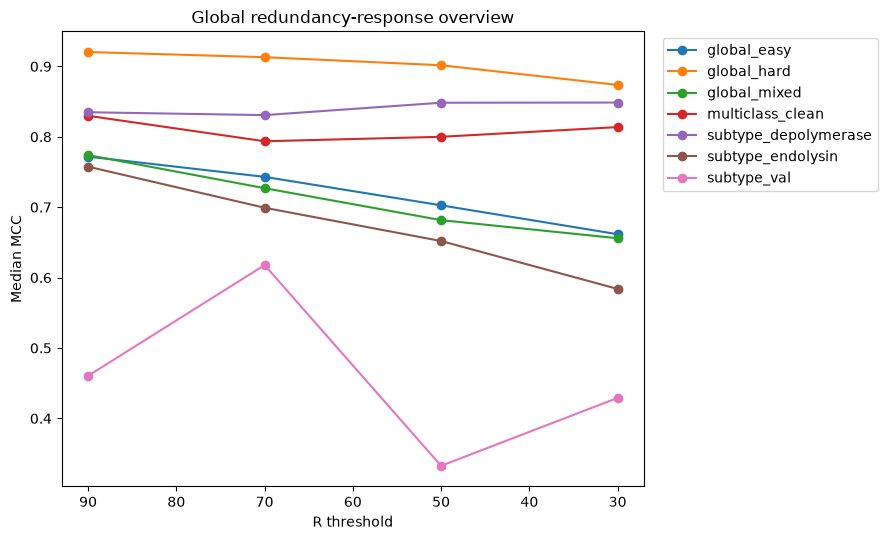

In [4]:
overview = (
    master.groupby(["task", "R"], as_index=False)
    .agg(
        mcc_median=("mcc", "median"),
        mcc_mean=("mcc", "mean"),
        mcc_min=("mcc", "min"),
        mcc_max=("mcc", "max"),
    )
)

display(overview)

fig, ax = plt.subplots(figsize=(9, 5.5))
for task, g in overview.groupby("task"):
    g = g.set_index("R").reindex(R_LEVELS)
    ax.plot(
        R_LEVELS,
        g["mcc_median"],
        marker="o",
        label=task,
    )

ax.set_xlabel("R threshold")
ax.set_ylabel("Median MCC")
ax.set_title("Global redundancy-response overview")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.invert_xaxis()
plt.tight_layout()
plt.show()

## 3. Complete R curves at fixed S

For each `task × representation × algorithm`, four curves are available:

\[
M(R\mid S=90),\; M(R\mid S=70),\; M(R\mid S=50),\; M(R\mid S=30)
\]

Edit the parameters below to inspect any model family.

TASK           = global_easy
REPRESENTATION = esm2_t30_150m
ALGORITHM      = XGB
METRIC         = mcc


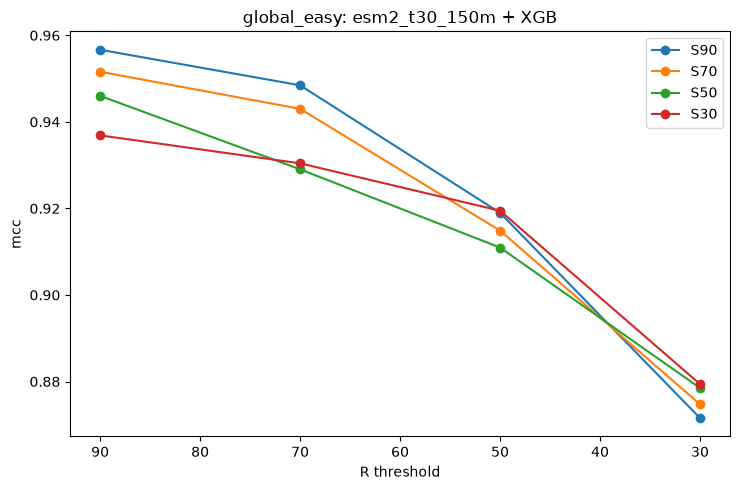

In [5]:
TASK = "global_easy"
REPRESENTATION = "esm2_t30_150m" if "esm2_t30_150m" in master["representation"].unique() else sorted(master["representation"].unique())[0]
ALGORITHM = "XGB" if "XGB" in master["algorithm"].unique() else sorted(master["algorithm"].unique())[0]
METRIC = "mcc"

print("TASK           =", TASK)
print("REPRESENTATION =", REPRESENTATION)
print("ALGORITHM      =", ALGORITHM)
print("METRIC         =", METRIC)

g = master[
    master["task"].eq(TASK)
    & master["representation"].eq(REPRESENTATION)
    & master["algorithm"].eq(ALGORITHM)
].copy()

fig, ax = plt.subplots(figsize=(7.5, 5))
for s in S_LEVELS:
    curve = (
        g[g["S"].eq(s)]
        .set_index("R")
        .reindex(R_LEVELS)
    )
    ax.plot(
        R_LEVELS,
        curve[METRIC],
        marker="o",
        label=f"S{s}",
    )

ax.set_xlabel("R threshold")
ax.set_ylabel(METRIC)
ax.set_title(f"{TASK}: {REPRESENTATION} + {ALGORITHM}")
ax.legend()
ax.invert_xaxis()
plt.tight_layout()
plt.show()

## 4. All six R contrasts at fixed S

In [6]:
r_metrics = sorted(r_deltas["metric"].dropna().unique())
print("Metrics in Stage12B R-delta table:", r_metrics)

R_METRIC = "mcc" if "mcc" in r_metrics else r_metrics[0]

rd = r_deltas[r_deltas["metric"].eq(R_METRIC)].copy()

contrast_summary = (
    rd.groupby(["R_from", "R_to"], as_index=False)
    .agg(
        n=("delta", "size"),
        mean_delta=("delta", "mean"),
        median_delta=("delta", "median"),
        std_delta=("delta", "std"),
        q25=("delta", lambda x: x.quantile(0.25)),
        q75=("delta", lambda x: x.quantile(0.75)),
        min_delta=("delta", "min"),
        max_delta=("delta", "max"),
        fraction_negative=("delta", lambda x: (x < 0).mean()),
        fraction_positive=("delta", lambda x: (x > 0).mean()),
    )
)

contrast_summary["contrast"] = (
    "R"
    + contrast_summary["R_from"].astype(str)
    + "→R"
    + contrast_summary["R_to"].astype(str)
)

display(contrast_summary)

Metrics in Stage12B R-delta table: ['ap', 'ap_gain', 'macro_f1', 'mcc']


,R_from,R_to,n,mean_delta,median_delta,std_delta,q25,q75,min_delta,max_delta,fraction_negative,fraction_positive,contrast
0,50,30,560,-0.013584,-0.022173,0.066795,-0.043332,0.006524,-0.332676,0.418899,0.685714,0.282143,R50→R30
1,70,30,560,-0.054919,-0.046893,0.089721,-0.081794,-0.005116,-0.616528,0.182626,0.769643,0.208929,R70→R30
2,70,50,560,-0.041335,-0.023619,0.094041,-0.049133,0.000000,-0.689417,0.332676,0.725000,0.248214,R70→R50
3,90,30,560,-0.073171,-0.070347,0.106424,-0.119882,-0.018135,-0.513991,0.514487,0.821429,0.164286,R90→R30
4,90,50,560,-0.059587,-0.044738,0.103477,-0.086495,-0.014560,-0.678785,0.567878,0.817857,0.162500,R90→R50
5,90,70,560,-0.018252,-0.022014,0.073930,-0.052118,0.000000,-0.389728,0.482710,0.735714,0.248214,R90→R70


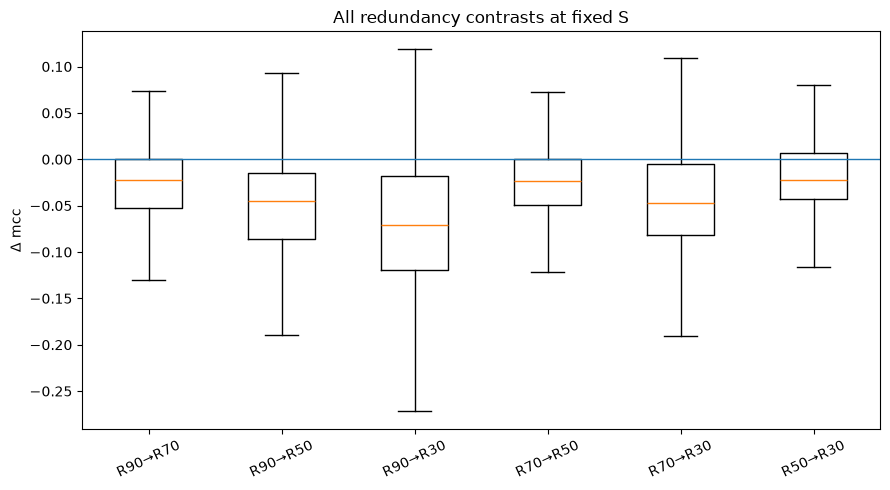

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
ordered_pairs = [
    (90, 70), (90, 50), (90, 30),
    (70, 50), (70, 30),
    (50, 30),
]
data = [
    rd.loc[
        rd["R_from"].eq(a) & rd["R_to"].eq(b),
        "delta"
    ].dropna().to_numpy()
    for a, b in ordered_pairs
]
labels = [f"R{a}→R{b}" for a, b in ordered_pairs]

ax.boxplot(data, tick_labels=labels, showfliers=False)
ax.axhline(0, linewidth=1)
ax.set_ylabel(f"Δ {R_METRIC}")
ax.set_title("All redundancy contrasts at fixed S")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## 5. Stepwise redundancy effects

The consecutive transitions:

- `R90→R70`
- `R70→R50`
- `R50→R30`

reveal whether degradation is smooth or concentrated in a specific threshold interval.

In [8]:
step_pairs = [(90, 70), (70, 50), (50, 30)]

step_summary = (
    rd[
        rd.apply(
            lambda x: (int(x["R_from"]), int(x["R_to"])) in step_pairs,
            axis=1,
        )
    ]
    .groupby(["R_from", "R_to"], as_index=False)
    .agg(
        mean_delta=("delta", "mean"),
        median_delta=("delta", "median"),
        mean_abs_delta=("delta", lambda x: x.abs().mean()),
        median_abs_delta=("delta", lambda x: x.abs().median()),
        fraction_negative=("delta", lambda x: (x < 0).mean()),
    )
)

step_summary["step"] = (
    "R"
    + step_summary["R_from"].astype(str)
    + "→R"
    + step_summary["R_to"].astype(str)
)

display(step_summary)

,R_from,R_to,mean_delta,median_delta,mean_abs_delta,median_abs_delta,fraction_negative,step
0,50,30,-0.013584,-0.022173,0.044756,0.031941,0.685714,R50→R30
1,70,50,-0.041335,-0.023619,0.055452,0.030822,0.725000,R70→R50
2,90,70,-0.018252,-0.022014,0.049466,0.034586,0.735714,R90→R70


## 6. Which redundancy transition is the dominant one for each model family?

In [9]:
step_rd = rd[
    rd.apply(
        lambda x: (int(x["R_from"]), int(x["R_to"])) in step_pairs,
        axis=1,
    )
].copy()

step_rd["abs_delta"] = step_rd["delta"].abs()
step_rd["step"] = (
    "R" + step_rd["R_from"].astype(str)
    + "→R" + step_rd["R_to"].astype(str)
)

dominant_step = (
    step_rd.sort_values(
        ["task", "representation", "algorithm", "S_fixed", "abs_delta"],
        ascending=[True, True, True, True, False],
        kind="stable",
    )
    .groupby(
        ["task", "representation", "algorithm", "S_fixed"],
        as_index=False,
    )
    .first()
)

display(
    dominant_step["step"]
    .value_counts(normalize=True)
    .rename("fraction_of_model×S_groups")
    .to_frame()
)

,fraction_of_model×S_groups
step,
R50→R30,0.375000
R90→R70,0.342857
R70→R50,0.282143


In [10]:
dominant_by_task = (
    dominant_step.groupby(["task", "step"])
    .size()
    .rename("n")
    .reset_index()
)

dominant_by_task["fraction_within_task"] = (
    dominant_by_task["n"]
    / dominant_by_task.groupby("task")["n"].transform("sum")
)

display(
    dominant_by_task.sort_values(
        ["task", "fraction_within_task"],
        ascending=[True, False],
    )
)

,task,step,n,fraction_within_task
0,global_easy,R50→R30,36,0.4500
1,global_easy,R70→R50,25,0.3125
2,global_easy,R90→R70,19,0.2375
3,global_hard,R50→R30,44,0.5500
5,global_hard,R90→R70,21,0.2625
4,global_hard,R70→R50,15,0.1875
8,global_mixed,R90→R70,31,0.3875
6,global_mixed,R50→R30,30,0.3750
7,global_mixed,R70→R50,19,0.2375
11,multiclass_clean,R90→R70,44,0.5500


## 7. Monotonicity and response-shape classification

For each `task × representation × algorithm × S`, classify the four-point MCC trajectory as:

- `monotonic_decrease`: MCC never improves as R becomes stricter;
- `monotonic_increase`: MCC never worsens;
- `flat`: changes are negligible within tolerance;
- `nonmonotonic`: direction reverses.

A small tolerance avoids classifying numerical noise as biological structure.

In [11]:
MONOTONIC_TOL = 0.005

shape_rows = []

for keys, grp in master.groupby(
    ["task", "representation", "algorithm", "S"]
):
    task, rep, alg, s = keys

    curve = (
        grp.set_index("R")
        .reindex(R_LEVELS)["mcc"]
        .astype(float)
    )

    if curve.isna().any():
        continue

    values = curve.to_numpy()
    diffs = np.diff(values)  # order: 90 -> 70 -> 50 -> 30

    if np.all(np.abs(diffs) <= MONOTONIC_TOL):
        shape = "flat"
    elif np.all(diffs <= MONOTONIC_TOL):
        shape = "monotonic_decrease"
    elif np.all(diffs >= -MONOTONIC_TOL):
        shape = "monotonic_increase"
    else:
        shape = "nonmonotonic"

    shape_rows.append(
        {
            "task": task,
            "representation": rep,
            "algorithm": alg,
            "S": s,
            "shape": shape,
            "R90": values[0],
            "R70": values[1],
            "R50": values[2],
            "R30": values[3],
            "delta_R30_minus_R90": values[3] - values[0],
            "max_step_abs": float(np.max(np.abs(diffs))),
        }
    )

shape_df = pd.DataFrame(shape_rows)

display(
    shape_df["shape"]
    .value_counts(normalize=True)
    .rename("fraction")
    .to_frame()
)

display(
    pd.crosstab(
        shape_df["task"],
        shape_df["shape"],
        normalize="index",
    )
)

,fraction
shape,
monotonic_decrease,0.503571
nonmonotonic,0.444643
monotonic_increase,0.041071
flat,0.010714


shape,flat,monotonic_decrease,monotonic_increase,nonmonotonic
task,,,,
global_easy,0.000,0.7625,0.0000,0.2375
global_hard,0.000,0.6875,0.0000,0.3125
global_mixed,0.000,0.8500,0.0000,0.1500
multiclass_clean,0.000,0.1000,0.0125,0.8875
subtype_depolymerase,0.000,0.0875,0.2375,0.6750
subtype_endolysin,0.000,0.9250,0.0000,0.0750
subtype_val,0.075,0.1125,0.0375,0.7750


## 8. Performance retention relative to R90

In [12]:
retention_rows = []

for keys, grp in master.groupby(
    ["task", "representation", "algorithm", "S"]
):
    task, rep, alg, s = keys
    lookup = dict(zip(grp["R"].astype(int), grp["mcc"].astype(float)))

    if 90 not in lookup:
        continue

    baseline = lookup[90]

    for r in R_LEVELS:
        if r not in lookup:
            continue

        retention_rows.append(
            {
                "task": task,
                "representation": rep,
                "algorithm": alg,
                "S": s,
                "R": r,
                "mcc": lookup[r],
                "delta_from_R90": lookup[r] - baseline,
                "fraction_of_R90": (
                    lookup[r] / baseline
                    if baseline != 0
                    else np.nan
                ),
            }
        )

retention = pd.DataFrame(retention_rows)

display(
    retention.groupby("R")["delta_from_R90"]
    .agg(["mean", "median", "std", "min", "max"])
)

,mean,median,std,min,max
R,,,,,
30,-0.073171,-0.070347,0.106424,-0.513991,0.514487
50,-0.059587,-0.044738,0.103477,-0.678785,0.567878
70,-0.018252,-0.022014,0.073930,-0.389728,0.482710
90,0.000000,0.000000,0.000000,0.000000,0.000000


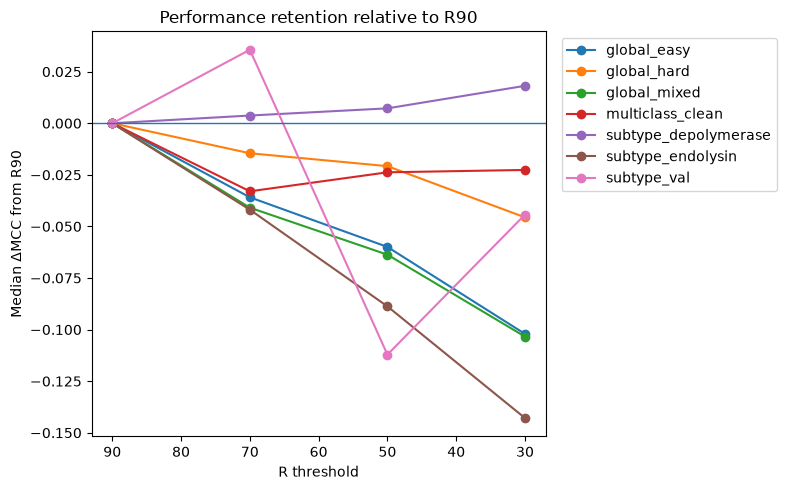

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
for task, g in retention.groupby("task"):
    summary = (
        g.groupby("R")["delta_from_R90"]
        .median()
        .reindex(R_LEVELS)
    )
    ax.plot(
        R_LEVELS,
        summary,
        marker="o",
        label=task,
    )

ax.axhline(0, linewidth=1)
ax.set_xlabel("R threshold")
ax.set_ylabel("Median ΔMCC from R90")
ax.set_title("Performance retention relative to R90")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.invert_xaxis()
plt.tight_layout()
plt.show()

## 9. Which tasks are most redundancy-sensitive?

In [14]:
extreme_r = rd[
    rd["R_from"].eq(90)
    & rd["R_to"].eq(30)
].copy()

task_sensitivity = (
    extreme_r.groupby("task", as_index=False)
    .agg(
        mean_delta=("delta", "mean"),
        median_delta=("delta", "median"),
        mean_abs_delta=("delta", lambda x: x.abs().mean()),
        median_abs_delta=("delta", lambda x: x.abs().median()),
        min_delta=("delta", "min"),
        max_delta=("delta", "max"),
        fraction_negative=("delta", lambda x: (x < 0).mean()),
    )
    .sort_values("median_abs_delta", ascending=False)
)

display(task_sensitivity)

,task,mean_delta,median_delta,mean_abs_delta,median_abs_delta,min_delta,max_delta,fraction_negative
5,subtype_endolysin,-0.161694,-0.142878,0.161694,0.142878,-0.513991,-0.062069,1.0000
6,subtype_val,-0.067767,-0.044254,0.149505,0.111745,-0.497191,0.514487,0.5875
2,global_mixed,-0.117770,-0.103402,0.117770,0.103402,-0.350685,-0.025496,1.0000
0,global_easy,-0.112667,-0.102103,0.112667,0.102103,-0.372241,-0.020104,1.0000
1,global_hard,-0.053908,-0.045614,0.054183,0.045614,-0.154351,0.011016,0.9875
4,subtype_depolymerase,0.024989,0.018144,0.046881,0.037814,-0.092780,0.182626,0.3750
3,multiclass_clean,-0.023381,-0.022622,0.036300,0.030760,-0.138367,0.136891,0.8000


## 10. Which representations are most redundancy-sensitive?

In [15]:
rep_sensitivity = (
    extreme_r.groupby("representation", as_index=False)
    .agg(
        mean_delta=("delta", "mean"),
        median_delta=("delta", "median"),
        mean_abs_delta=("delta", lambda x: x.abs().mean()),
        median_abs_delta=("delta", lambda x: x.abs().median()),
        min_delta=("delta", "min"),
        max_delta=("delta", "max"),
        fraction_negative=("delta", lambda x: (x < 0).mean()),
    )
    .sort_values("median_abs_delta", ascending=False)
)

display(rep_sensitivity)

,representation,mean_delta,median_delta,mean_abs_delta,median_abs_delta,min_delta,max_delta,fraction_negative
2,onehot_1024,-0.121581,-0.095149,0.135181,0.098644,-0.513991,0.182626,0.850000
3,roxy_48,-0.068453,-0.077351,0.096382,0.086618,-0.497191,0.240233,0.785714
1,esm2_t6_8m,-0.051633,-0.056965,0.089260,0.083029,-0.291634,0.514487,0.800000
0,esm2_t30_150m,-0.051018,-0.056807,0.067178,0.062409,-0.278173,0.176985,0.850000


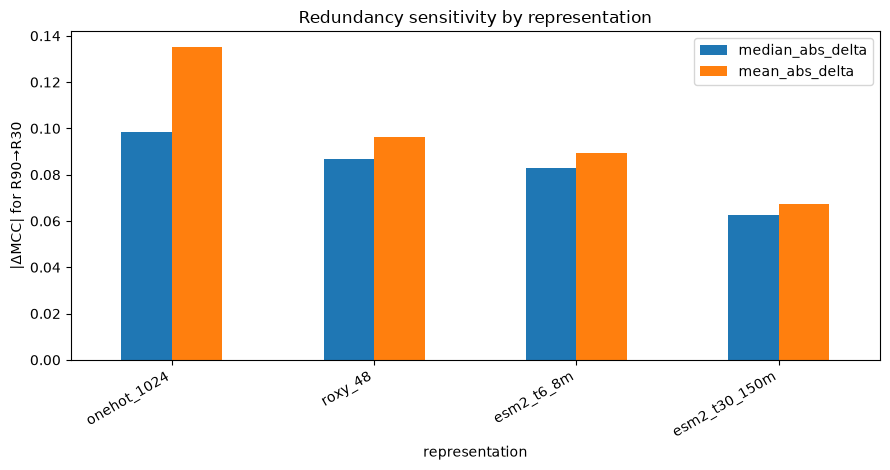

In [16]:
rep_sensitivity.set_index("representation")[
    ["median_abs_delta", "mean_abs_delta"]
].plot(kind="bar", figsize=(9, 4.8))

plt.ylabel("|ΔMCC| for R90→R30")
plt.title("Redundancy sensitivity by representation")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 11. Which algorithms are most redundancy-sensitive?

In [17]:
alg_sensitivity = (
    extreme_r.groupby("algorithm", as_index=False)
    .agg(
        mean_delta=("delta", "mean"),
        median_delta=("delta", "median"),
        mean_abs_delta=("delta", lambda x: x.abs().mean()),
        median_abs_delta=("delta", lambda x: x.abs().median()),
        min_delta=("delta", "min"),
        max_delta=("delta", "max"),
        fraction_negative=("delta", lambda x: (x < 0).mean()),
    )
    .sort_values("median_abs_delta", ascending=False)
)

display(alg_sensitivity)

,algorithm,mean_delta,median_delta,mean_abs_delta,median_abs_delta,min_delta,max_delta,fraction_negative
3,RF,-0.063485,-0.081927,0.094928,0.091442,-0.435370,0.240233,0.776786
0,KNN,-0.106397,-0.083245,0.126066,0.088282,-0.513991,0.514487,0.892857
4,XGB,-0.076797,-0.076951,0.095445,0.078729,-0.437966,0.243086,0.812500
2,MLP,-0.074506,-0.071688,0.091819,0.076000,-0.339206,0.445389,0.857143
1,LR,-0.044670,-0.051464,0.076742,0.062644,-0.339206,0.376532,0.767857


# 12. Reconstruct the amount and structure of training information

`R` changes more than a label on the experiment: it changes how many non-redundant entities and clusters remain available.

This section reconstructs, for every `task × R × S` cell:

- total eligible entities;
- train/test counts;
- train/test cluster counts;
- optional positive support when a recognizable binary-label column exists.

The notebook reads the frozen `data/predictive_universe/.../eligible_entities.tsv.gz` files directly.

In [18]:
PREDICTIVE_ROOT = ROOT / "data/predictive_universe"
COUNTS_CACHE = CACHE_DIR / "rq2_predictive_universe_counts.tsv"
FORCE_RECOUNT = False

def infer_split_column(df):
    for c in ["split", "outer_split", "partition", "set"]:
        if c in df.columns:
            return c
    raise KeyError(f"No split column found. Columns: {list(df.columns)}")

def infer_cluster_column(df):
    for c in ["cluster_id", "mmseqs_cluster_id", "cluster"]:
        if c in df.columns:
            return c
    return None

def infer_binary_label_column(df):
    candidates = [
        "y",
        "y_true",
        "label",
        "target",
        "binary_label",
        "class_label",
    ]
    for c in candidates:
        if c in df.columns:
            vals = set(pd.Series(df[c]).dropna().astype(str).str.lower().unique())
            if vals <= {"0", "1", "0.0", "1.0", "positive", "negative", "p", "n"}:
                return c
    return None

def count_predictive_universe():
    rows = []

    for task, task_path in TASK_PATHS.items():
        for r in R_LEVELS:
            for s in S_LEVELS:
                path = (
                    PREDICTIVE_ROOT
                    / task_path
                    / f"R{r}_S{s}"
                    / "eligible_entities.tsv.gz"
                )

                if not path.is_file():
                    rows.append(
                        {
                            "task": task,
                            "R": r,
                            "S": s,
                            "found": False,
                            "path": str(path),
                        }
                    )
                    continue

                df = pd.read_csv(path, sep="\t", low_memory=False)
                split_col = infer_split_column(df)
                cluster_col = infer_cluster_column(df)
                label_col = infer_binary_label_column(df) if task in BINARY_TASKS else None

                split_norm = df[split_col].astype(str).str.lower()
                train_mask = split_norm.eq("train")
                test_mask = split_norm.eq("test")

                row = {
                    "task": task,
                    "R": r,
                    "S": s,
                    "found": True,
                    "path": str(path),
                    "n_total": len(df),
                    "n_train": int(train_mask.sum()),
                    "n_test": int(test_mask.sum()),
                    "n_clusters_total": (
                        df[cluster_col].nunique()
                        if cluster_col
                        else np.nan
                    ),
                    "n_clusters_train": (
                        df.loc[train_mask, cluster_col].nunique()
                        if cluster_col
                        else np.nan
                    ),
                    "n_clusters_test": (
                        df.loc[test_mask, cluster_col].nunique()
                        if cluster_col
                        else np.nan
                    ),
                    "cluster_column": cluster_col or "",
                    "label_column": label_col or "",
                }

                if label_col:
                    y = df[label_col].astype(str).str.lower()
                    pos = y.isin({"1", "1.0", "positive", "p"})

                    row["n_positive_total"] = int(pos.sum())
                    row["n_positive_train"] = int((pos & train_mask).sum())
                    row["n_positive_test"] = int((pos & test_mask).sum())

                rows.append(row)

    return pd.DataFrame(rows)

if COUNTS_CACHE.is_file() and not FORCE_RECOUNT:
    counts = pd.read_csv(COUNTS_CACHE, sep="\t", low_memory=False)
    print("Loaded:", COUNTS_CACHE)
else:
    counts = count_predictive_universe()
    counts.to_csv(COUNTS_CACHE, sep="\t", index=False)
    print("Wrote:", COUNTS_CACHE)

print("Cells found:", counts["found"].sum(), "/", len(counts))
display(counts.head())

Wrote: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq2_predictive_universe_counts.tsv
Cells found: 112 / 112


,task,R,S,found,path,n_total,n_train,n_test,n_clusters_total,n_clusters_train,n_clusters_test,cluster_column,label_column,n_positive_total,n_positive_train,n_positive_test
0,global_easy,90,90,True,/home/david/Desktop/colabs/inta_project/phagel...,30092,21049,9043,30083,21041,9042,cluster_id,label,4763.0,3324.0,1439.0
1,global_easy,90,70,True,/home/david/Desktop/colabs/inta_project/phagel...,30092,21050,9042,21485,15029,6456,cluster_id,label,4763.0,3321.0,1442.0
2,global_easy,90,50,True,/home/david/Desktop/colabs/inta_project/phagel...,30092,21068,9024,14786,10284,4502,cluster_id,label,4763.0,3380.0,1383.0
3,global_easy,90,30,True,/home/david/Desktop/colabs/inta_project/phagel...,30092,21076,9016,8995,6238,2757,cluster_id,label,4763.0,3284.0,1479.0
4,global_easy,70,90,True,/home/david/Desktop/colabs/inta_project/phagel...,21512,15058,6454,21507,15055,6452,cluster_id,label,3463.0,2437.0,1026.0


## 13. How much information is removed as R becomes stricter?

At fixed `S`, quantify changes in:

- training entities;
- training clusters.

This directly contextualizes the performance deltas.

In [19]:
count_step_rows = []

for (task, s), grp in counts[counts["found"]].groupby(["task", "S"]):
    lookup = grp.set_index("R").to_dict("index")

    for r_from, r_to in [
        (90, 70), (90, 50), (90, 30),
        (70, 50), (70, 30),
        (50, 30),
    ]:
        if r_from not in lookup or r_to not in lookup:
            continue

        a = lookup[r_from]
        b = lookup[r_to]

        row = {
            "task": task,
            "S_fixed": s,
            "R_from": r_from,
            "R_to": r_to,
            "n_train_from": a.get("n_train", np.nan),
            "n_train_to": b.get("n_train", np.nan),
            "n_clusters_train_from": a.get("n_clusters_train", np.nan),
            "n_clusters_train_to": b.get("n_clusters_train", np.nan),
        }

        if pd.notna(row["n_train_from"]) and row["n_train_from"] > 0:
            row["fraction_train_removed"] = (
                row["n_train_from"] - row["n_train_to"]
            ) / row["n_train_from"]
        else:
            row["fraction_train_removed"] = np.nan

        if (
            pd.notna(row["n_clusters_train_from"])
            and row["n_clusters_train_from"] > 0
        ):
            row["fraction_train_clusters_removed"] = (
                row["n_clusters_train_from"] - row["n_clusters_train_to"]
            ) / row["n_clusters_train_from"]
        else:
            row["fraction_train_clusters_removed"] = np.nan

        count_step_rows.append(row)

count_steps = pd.DataFrame(count_step_rows)

display(
    count_steps.groupby(["R_from", "R_to"])[
        ["fraction_train_removed", "fraction_train_clusters_removed"]
    ]
    .agg(["mean", "median", "min", "max"])
)

fraction_train_removed                               fraction_train_clusters_removed                              
                              mean    median       min       max                            mean    median       min       max
R_from R_to                                                                                                                   
50     30                 0.364982  0.382495  0.295649  0.392722                        0.274741  0.379937 -0.000609  0.392546
70     30                 0.557142  0.571339  0.494891  0.583278                        0.369657  0.443292 -0.011142  0.583195
       50                 0.303121  0.306481  0.281460  0.313954                        0.150588  0.146212 -0.027855  0.313849
90     30                 0.679748  0.692519  0.626940  0.701886                        0.399346  0.440400 -0.007043  0.701773
       50                 0.496411  0.502997  0.469828  0.509098                        0.197533  0.143699 -0.011744  0.509054
       70                 0.277480  0.282846  0.254877  0.286224                        0.067869 -0.000193 -0.009483  0.284626

## 14. Performance loss versus amount of training data removed

In [20]:
rd_with_counts = rd.merge(
    count_steps,
    on=["task", "S_fixed", "R_from", "R_to"],
    how="left",
)

rd_with_counts["mcc_loss"] = -rd_with_counts["delta"]

rd_with_counts["mcc_loss_per_10pct_train_removed"] = np.where(
    rd_with_counts["fraction_train_removed"] > 0,
    rd_with_counts["mcc_loss"]
    / rd_with_counts["fraction_train_removed"]
    * 0.10,
    np.nan,
)

rd_with_counts["mcc_loss_per_10pct_clusters_removed"] = np.where(
    rd_with_counts["fraction_train_clusters_removed"] > 0,
    rd_with_counts["mcc_loss"]
    / rd_with_counts["fraction_train_clusters_removed"]
    * 0.10,
    np.nan,
)

display(
    rd_with_counts[
        [
            "task", "representation", "algorithm", "S_fixed",
            "R_from", "R_to", "delta",
            "fraction_train_removed",
            "fraction_train_clusters_removed",
            "mcc_loss_per_10pct_train_removed",
            "mcc_loss_per_10pct_clusters_removed",
        ]
    ].head()
)

,task,representation,algorithm,S_fixed,R_from,R_to,delta,fraction_train_removed,fraction_train_clusters_removed,mcc_loss_per_10pct_train_removed,mcc_loss_per_10pct_clusters_removed
0,global_easy,esm2_t30_150m,KNN,90,90,70,-0.015849,0.284622,0.284492,0.005568,0.005571
1,global_easy,esm2_t30_150m,KNN,90,90,50,-0.039922,0.509098,0.509054,0.007842,0.007842
2,global_easy,esm2_t30_150m,KNN,90,90,30,-0.078885,0.701886,0.701773,0.011239,0.011241
3,global_easy,esm2_t30_150m,KNN,90,70,50,-0.024074,0.313787,0.313849,0.007672,0.007670
4,global_easy,esm2_t30_150m,KNN,90,70,30,-0.063036,0.583278,0.583195,0.010807,0.010809


In [21]:
# Consecutive steps only: easier to interpret because the amount removed is local.
step_with_counts = rd_with_counts[
    rd_with_counts.apply(
        lambda x: (int(x["R_from"]), int(x["R_to"])) in step_pairs,
        axis=1,
    )
].copy()

display(
    step_with_counts.groupby(["R_from", "R_to"])[
        [
            "delta",
            "fraction_train_removed",
            "fraction_train_clusters_removed",
            "mcc_loss_per_10pct_train_removed",
            "mcc_loss_per_10pct_clusters_removed",
        ]
    ]
    .agg(["mean", "median", "std", "min", "max"])
)

delta                                         fraction_train_removed                                         fraction_train_clusters_removed                                          \
                 mean    median       std       min       max                   mean    median       std       min       max                            mean    median       std       min       max   
R_from R_to                                                                                                                                                                                            
50     30   -0.013584 -0.022173  0.066795 -0.332676  0.418899               0.364982  0.382495  0.034435  0.295649  0.392722                        0.274741  0.379937  0.158394 -0.000609  0.392546   
70     50   -0.041335 -0.023619  0.094041 -0.689417  0.332676               0.303121  0.306481  0.010245  0.281460  0.313954                        0.150588  0.146212  0.153340 -0.027855  0.313849   
90     70   -0.018252 -0.022014  0.073930 -0.389728  0.482710               0.277480  0.282846  0.010080  0.254877  0.286224                        0.067869 -0.000193  0.121463 -0.009483  0.284626   

            mcc_loss_per_10pct_train_removed                                         mcc_loss_per_10pct_clusters_removed                                            
                                        mean    median       std       min       max                                mean    median       std        min        max  
R_from R_to                                                                                                                                                         
50     30                           0.003804  0.006238  0.017518 -0.108053  0.085637                            0.162812  0.007028  1.228270 -11.569552  11.432820  
70     50                           0.013402  0.007578  0.030575 -0.108230  0.223493                            0.528049  0.015110  1.644281  -2.337665  13.007673  
90     70                           0.006593  0.008020  0.026164 -0.169334  0.137083                           -0.183367  0.008697  2.005430 -10.363701  15.360169

## 15. Are larger reductions in training size associated with larger MCC losses?

In [22]:
corr_rows = []

for keys, grp in step_with_counts.groupby(
    ["task", "representation", "algorithm"]
):
    task, rep, alg = keys

    for predictor in [
        "fraction_train_removed",
        "fraction_train_clusters_removed",
    ]:
        x = grp[[predictor, "mcc_loss"]].dropna()

        if len(x) < 4 or x[predictor].nunique() < 2:
            rho = np.nan
        else:
            rho = x[predictor].corr(
                x["mcc_loss"],
                method="spearman",
            )

        corr_rows.append(
            {
                "task": task,
                "representation": rep,
                "algorithm": alg,
                "predictor": predictor,
                "n": len(x),
                "spearman_rho": rho,
            }
        )

quantity_correlations = pd.DataFrame(corr_rows)

display(
    quantity_correlations.groupby("predictor")["spearman_rho"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

,count,mean,median,std,min,max
predictor,,,,,,
fraction_train_clusters_removed,140,0.200874,0.216783,0.345507,-0.545860,0.853147
fraction_train_removed,140,0.012220,0.010490,0.447305,-0.874126,0.972028


## 16. Same removal, different model response?

If two representations lose very different MCC despite experiencing the same `task × R × S` reduction in training entities, then redundancy sensitivity cannot be explained by data quantity alone.

Compare normalized loss by representation.

In [23]:
quantity_normalized_rep = (
    step_with_counts.groupby("representation", as_index=False)
    .agg(
        median_mcc_loss=("mcc_loss", "median"),
        median_loss_per_10pct_train_removed=(
            "mcc_loss_per_10pct_train_removed",
            "median",
        ),
        median_loss_per_10pct_clusters_removed=(
            "mcc_loss_per_10pct_clusters_removed",
            "median",
        ),
        mean_loss_per_10pct_train_removed=(
            "mcc_loss_per_10pct_train_removed",
            "mean",
        ),
    )
    .sort_values(
        "median_loss_per_10pct_train_removed",
        ascending=False,
    )
)

display(quantity_normalized_rep)

,representation,median_mcc_loss,median_loss_per_10pct_train_removed,median_loss_per_10pct_clusters_removed,mean_loss_per_10pct_train_removed
2,onehot_1024,0.030999,0.010114,0.011109,0.013404
3,roxy_48,0.025435,0.007834,0.010694,0.007495
1,esm2_t6_8m,0.022348,0.007205,0.009903,0.005573
0,esm2_t30_150m,0.017551,0.005997,0.009057,0.005260


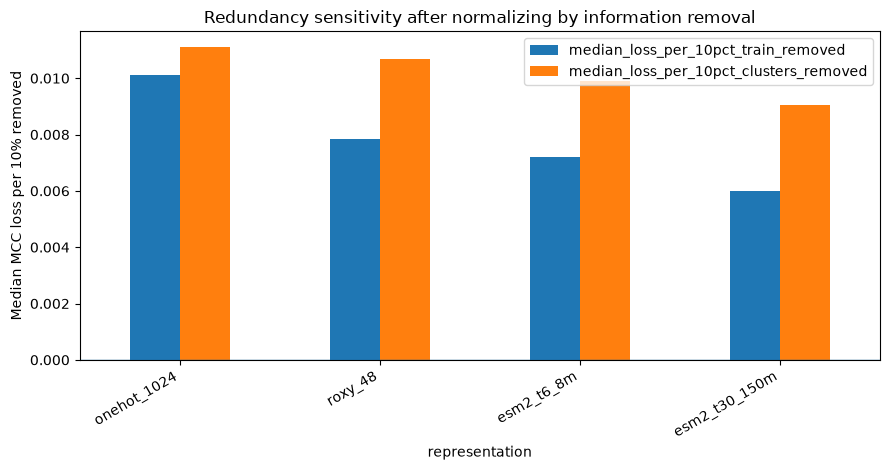

In [24]:
quantity_normalized_rep.set_index("representation")[
    [
        "median_loss_per_10pct_train_removed",
        "median_loss_per_10pct_clusters_removed",
    ]
].plot(kind="bar", figsize=(9, 4.8))

plt.axhline(0, linewidth=1)
plt.ylabel("Median MCC loss per 10% removed")
plt.title("Redundancy sensitivity after normalizing by information removal")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 17. R effect by S — does the redundancy response depend on split stringency?

In [25]:
extreme_by_s = (
    extreme_r.groupby("S_fixed", as_index=False)
    .agg(
        mean_delta=("delta", "mean"),
        median_delta=("delta", "median"),
        mean_abs_delta=("delta", lambda x: x.abs().mean()),
        median_abs_delta=("delta", lambda x: x.abs().median()),
        fraction_negative=("delta", lambda x: (x < 0).mean()),
    )
)

display(extreme_by_s)

,S_fixed,mean_delta,median_delta,mean_abs_delta,median_abs_delta,fraction_negative
0,30,-0.020187,-0.039645,0.080132,0.064053,0.664286
1,50,-0.067048,-0.069663,0.085161,0.081692,0.828571
2,70,-0.089129,-0.091481,0.099788,0.093130,0.864286
3,90,-0.116321,-0.084248,0.122919,0.087235,0.928571


This is only a **conditioning analysis**. Do not yet interpret differences across `S` as a formal `R×S` interaction; that belongs to the dedicated interaction RQ.

## 18. Binary-task AP-skill redundancy sensitivity

In [26]:
if "ap_skill" in master.columns:
    binary = master[master["task"].isin(BINARY_TASKS)].copy()

    ap_step_rows = []

    for keys, grp in binary.groupby(
        ["task", "representation", "algorithm", "S"]
    ):
        task, rep, alg, s = keys
        lookup = dict(
            zip(
                grp["R"].astype(int),
                grp["ap_skill"].astype(float),
            )
        )

        for r_from, r_to in [
            (90, 70), (90, 50), (90, 30),
            (70, 50), (70, 30),
            (50, 30),
        ]:
            if r_from in lookup and r_to in lookup:
                ap_step_rows.append(
                    {
                        "task": task,
                        "representation": rep,
                        "algorithm": alg,
                        "S_fixed": s,
                        "R_from": r_from,
                        "R_to": r_to,
                        "delta_ap_skill": (
                            lookup[r_to] - lookup[r_from]
                        ),
                    }
                )

    ap_r_deltas = pd.DataFrame(ap_step_rows)

    display(
        ap_r_deltas[
            ap_r_deltas["R_from"].eq(90)
            & ap_r_deltas["R_to"].eq(30)
        ]
        .groupby("task")["delta_ap_skill"]
        .agg(["mean", "median", "std", "min", "max"])
    )

,mean,median,std,min,max
task,,,,,
global_easy,-0.108460,-0.086692,0.081623,-0.403273,0.035252
global_hard,-0.022082,-0.015133,0.018490,-0.081596,0.011434
global_mixed,-0.118878,-0.099763,0.081686,-0.397119,0.045315
subtype_depolymerase,0.038470,0.029372,0.058074,-0.101076,0.204594
subtype_endolysin,-0.169090,-0.149750,0.103041,-0.565342,-0.048932
subtype_val,-0.040042,-0.045140,0.193360,-0.465259,0.552124


## 19. Low-support check for VAL

,task,R,S,representation,algorithm,mcc,n_positive,prevalence
1600,subtype_val,90,90,roxy_48,LR,0.121263,26.0,0.003174
1601,subtype_val,90,90,roxy_48,RF,0.391705,26.0,0.003174
1602,subtype_val,90,90,roxy_48,KNN,0.738944,26.0,0.003174
1603,subtype_val,90,90,roxy_48,XGB,0.712782,26.0,0.003174
1604,subtype_val,90,90,roxy_48,MLP,0.646245,26.0,0.003174


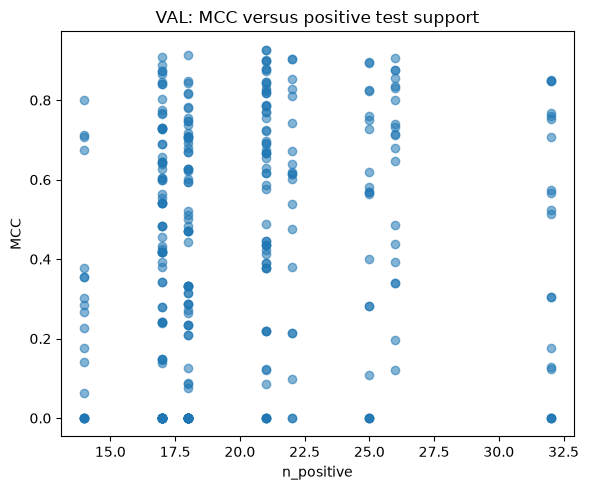

Spearman: 0.22592094554894349


In [27]:
val_cols = [
    c for c in [
        "task", "R", "S", "representation", "algorithm",
        "mcc", "n_test", "n_positive", "test_prevalence",
        "prevalence", "support_positive",
    ]
    if c in master.columns
]

val_df = master[
    master["task"].eq("subtype_val")
][val_cols].copy()

display(val_df.head())

support_candidates = [
    "n_positive",
    "support_positive",
]
val_support_col = next(
    (c for c in support_candidates if c in val_df.columns),
    None,
)

if val_support_col:
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(
        val_df[val_support_col],
        val_df["mcc"],
        alpha=0.55,
    )
    ax.set_xlabel(val_support_col)
    ax.set_ylabel("MCC")
    ax.set_title("VAL: MCC versus positive test support")
    plt.tight_layout()
    plt.show()

    print(
        "Spearman:",
        val_df[[val_support_col, "mcc"]]
        .dropna()
        .corr(method="spearman")
        .iloc[0, 1],
    )
else:
    print(
        "No positive-support column was found in supervised_master_results.tsv. "
        "Support-aware VAL interpretation will rely on the predictive-universe counts or the dedicated VAL RQ."
    )

# 20. RQ2 synthesis metrics

This section generates a compact evidence sheet for later Results writing.

The notebook should allow us to answer:

1. Does stricter redundancy control generally reduce performance?
2. Is the effect monotonic?
3. Which threshold transition is most damaging?
4. Which biological tasks are most/least redundancy-sensitive?
5. Which representations retain the most performance as redundancy is removed?
6. Which learners are most sensitive?
7. Does the effect remain large after normalizing by the amount of training information removed?
8. Is degradation better associated with entity loss or cluster loss?
9. Does the shape of the R response depend on S?
10. Which observed patterns are robust enough to carry into the *Briefings* narrative?

In [28]:
rq2_summary_rows = []

# Overall extreme effect.
x = extreme_r["delta"].dropna()
rq2_summary_rows.append(
    {
        "evidence": "overall_R90_to_R30",
        "group": "all",
        "median_delta_mcc": x.median(),
        "mean_delta_mcc": x.mean(),
        "median_abs_delta_mcc": x.abs().median(),
        "fraction_negative": (x < 0).mean(),
        "n": len(x),
    }
)

# By task.
for row in task_sensitivity.to_dict("records"):
    rq2_summary_rows.append(
        {
            "evidence": "R90_to_R30_by_task",
            "group": row["task"],
            "median_delta_mcc": row["median_delta"],
            "mean_delta_mcc": row["mean_delta"],
            "median_abs_delta_mcc": row["median_abs_delta"],
            "fraction_negative": row["fraction_negative"],
        }
    )

# By representation.
for row in rep_sensitivity.to_dict("records"):
    rq2_summary_rows.append(
        {
            "evidence": "R90_to_R30_by_representation",
            "group": row["representation"],
            "median_delta_mcc": row["median_delta"],
            "mean_delta_mcc": row["mean_delta"],
            "median_abs_delta_mcc": row["median_abs_delta"],
            "fraction_negative": row["fraction_negative"],
        }
    )

# Shape frequencies.
for shape, fraction in shape_df["shape"].value_counts(normalize=True).items():
    rq2_summary_rows.append(
        {
            "evidence": "response_shape",
            "group": shape,
            "fraction": fraction,
        }
    )

rq2_summary = pd.DataFrame(rq2_summary_rows)
display(rq2_summary)

SUMMARY_PATH = CACHE_DIR / "rq2_evidence_summary.tsv"
rq2_summary.to_csv(SUMMARY_PATH, sep="\t", index=False)

STEP_PATH = CACHE_DIR / "rq2_stepwise_with_information_loss.tsv"
step_with_counts.to_csv(STEP_PATH, sep="\t", index=False)

SHAPE_PATH = CACHE_DIR / "rq2_response_shapes.tsv"
shape_df.to_csv(SHAPE_PATH, sep="\t", index=False)

print("Saved:")
print(" ", SUMMARY_PATH)
print(" ", STEP_PATH)
print(" ", SHAPE_PATH)

,evidence,group,median_delta_mcc,mean_delta_mcc,median_abs_delta_mcc,fraction_negative,n,fraction
0,overall_R90_to_R30,all,-0.070347,-0.073171,0.080191,0.821429,560.0,NaN
1,R90_to_R30_by_task,subtype_endolysin,-0.142878,-0.161694,0.142878,1.000000,NaN,NaN
2,R90_to_R30_by_task,subtype_val,-0.044254,-0.067767,0.111745,0.587500,NaN,NaN
3,R90_to_R30_by_task,global_mixed,-0.103402,-0.117770,0.103402,1.000000,NaN,NaN
4,R90_to_R30_by_task,global_easy,-0.102103,-0.112667,0.102103,1.000000,NaN,NaN
5,R90_to_R30_by_task,global_hard,-0.045614,-0.053908,0.045614,0.987500,NaN,NaN
6,R90_to_R30_by_task,subtype_depolymerase,0.018144,0.024989,0.037814,0.375000,NaN,NaN
7,R90_to_R30_by_task,multiclass_clean,-0.022622,-0.023381,0.030760,0.800000,NaN,NaN
8,R90_to_R30_by_representation,onehot_1024,-0.095149,-0.121581,0.098644,0.850000,NaN,NaN
9,R90_to_R30_by_representation,roxy_48,-0.077351,-0.068453,0.086618,0.785714,NaN,NaN


Saved:
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq2_evidence_summary.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq2_stepwise_with_information_loss.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq2_response_shapes.tsv


## What this notebook should not conclude

Do not interpret a lower `R` as a pure “harder test split”. `R` changes the **available evidence itself** by reducing redundancy before the split.

Therefore the scientifically correct question is:

> **How does functional recognition change as redundant sequence support is progressively removed?**

not simply:

> “Does stricter redundancy filtering lower MCC?”

Likewise, any apparent `R×S` interaction observed here should be treated as a hypothesis for the dedicated interaction analysis rather than finalized in RQ2.